# 🌸 Clasificación de flores con una CNN

**Objetivo:** clasificar fotos de flores en 5 clases (margarita, diente de león, rosa, girasol, tulipán) con una Red Neuronal Convolucional entrenada desde cero en TensorFlow/Keras.

**Contenido:** 1) Dataset · 2) Exploración · 3) Preprocesamiento · 4) División · 5) Data Augmentation · 6) CNN y entrenamiento · 7) Gráficas · 8) Evaluación y matriz de confusión · 9) Predicciones · 10) Guardado.

> 💡 Activa GPU: *Entorno de ejecución → Cambiar tipo de entorno → T4 GPU*. En CPU funciona pero tarda bastante más.

## 0. Configuración

In [ ]:
import os, json, random, shutil, tarfile, urllib.request
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
sns.set_theme(style="whitegrid")
IMG_SIZE, BATCH = 128, 32
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0 | Keras: 3.13.2 | GPU: []


## 1. Selección y descripción del dataset

**Flowers** (`flower_photos`, publicado por el equipo de TensorFlow): ~3.670 fotografías reales de flores en 5 clases:
`daisy`, `dandelion`, `roses`, `sunflowers`, `tulips`.

- **Por qué este dataset:** son fotos reales (distintos fondos, luz y tamaños), es lo bastante pequeño para entrenar en minutos y lo bastante difícil como para que el **Data Augmentation** tenga sentido.
- **Tipo de problema:** clasificación multiclase de imágenes → salida `softmax` y `sparse_categorical_crossentropy`.

In [ ]:
URL = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
DATA_DIR, ROOT = Path("data"), Path("data/flower_photos")
if not ROOT.exists():
    DATA_DIR.mkdir(exist_ok=True)
    print("Descargando (~218 MB)...")
    urllib.request.urlretrieve(URL, DATA_DIR / "flower_photos.tgz")
    with tarfile.open(DATA_DIR / "flower_photos.tgz") as tar:
        try: tar.extractall(DATA_DIR, filter="data")
        except TypeError: tar.extractall(DATA_DIR)

CLASS_NAMES = ["daisy", "dandelion", "roses", "sunflowers", "tulips"]
NOMBRES_ES = {"daisy": "Margarita", "dandelion": "Diente de león", "roses": "Rosa", "sunflowers": "Girasol", "tulips": "Tulipán"}
NOMBRES = [NOMBRES_ES[c] for c in CLASS_NAMES]
ARCHIVO_ES = {"daisy": "margarita", "dandelion": "diente_de_leon", "roses": "rosa", "sunflowers": "girasol", "tulips": "tulipan"}
assert all((ROOT / c).is_dir() for c in CLASS_NAMES)

rows = [(str(p), i) for i, c in enumerate(CLASS_NAMES) for p in sorted((ROOT / c).iterdir()) if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]
df = pd.DataFrame(rows, columns=["path", "label"]); df["clase"] = df["label"].map(dict(enumerate(NOMBRES)))
print("Total de imágenes:", len(df))

Descargando (~218 MB)...
Total de imágenes: 3670


## 2. Exploración y visualización de las imágenes

clase
Margarita         633
Diente de león    898
Rosa              641
Girasol           699
Tulipán           799
Name: count, dtype: int64 

{'Margarita': 0.172, 'Diente de león': 0.245, 'Rosa': 0.175, 'Girasol': 0.19, 'Tulipán': 0.218}


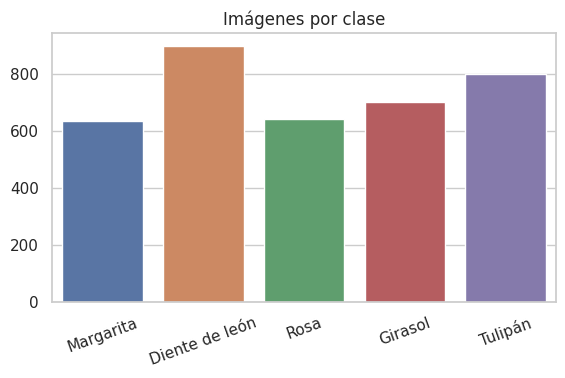

In [ ]:
conteo = df["clase"].value_counts().reindex(NOMBRES)
print(conteo, "\n"); print((conteo / len(df)).round(3).to_dict())
fig, ax = plt.subplots(figsize=(6.5, 3.5))
sns.barplot(x=conteo.index, y=conteo.values, hue=conteo.index, legend=False, ax=ax); ax.set_title("Imágenes por clase"); ax.set_xlabel(""); plt.xticks(rotation=20); plt.show()

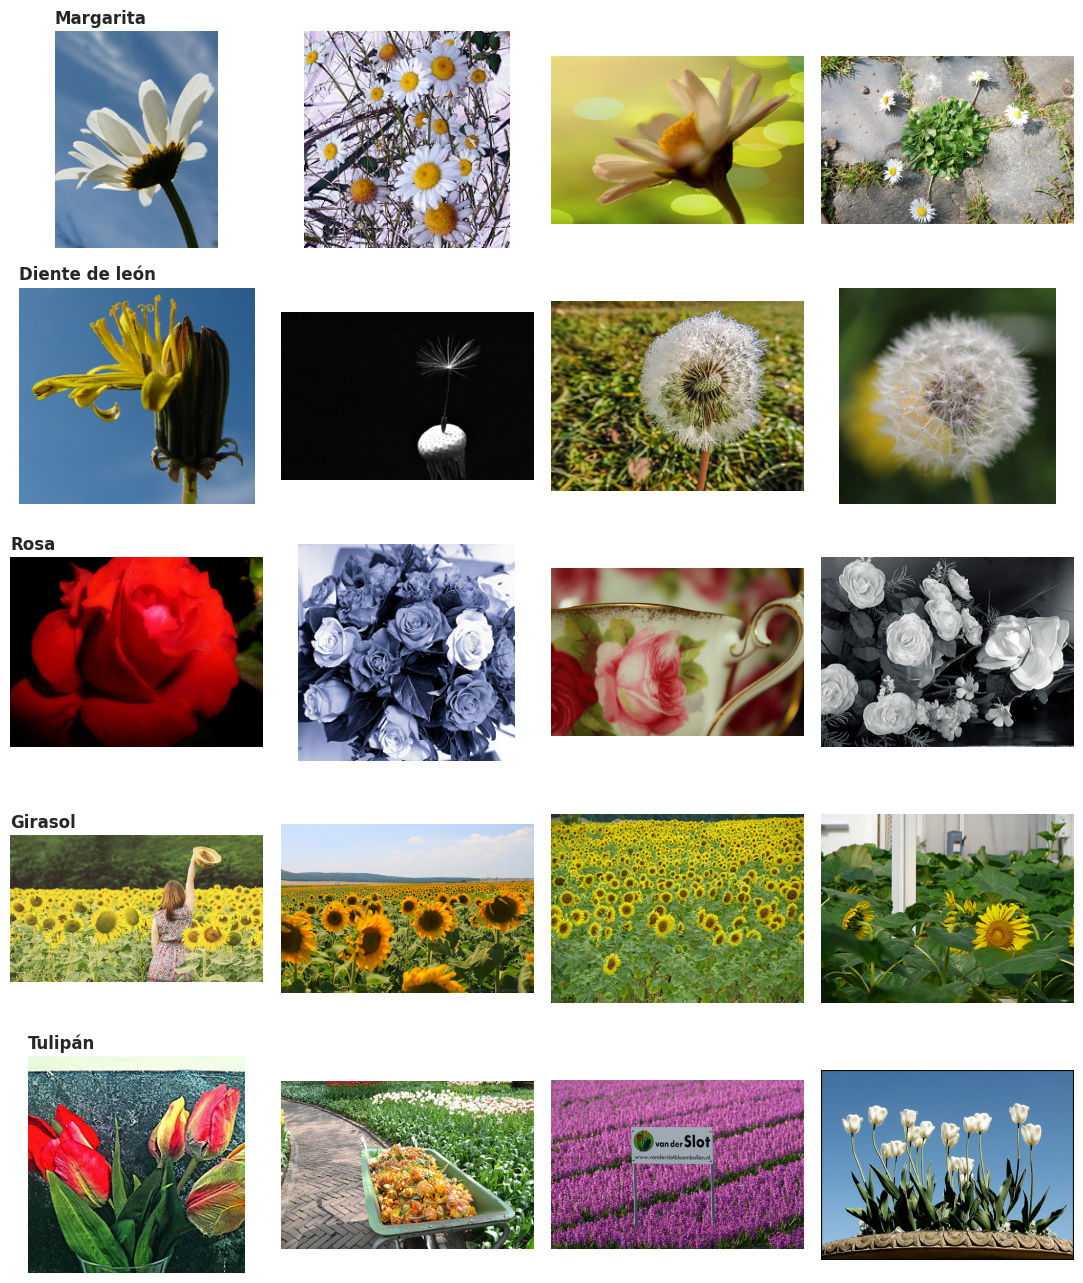

In [ ]:
# 4 imágenes aleatorias por clase
fig, axes = plt.subplots(5, 4, figsize=(11, 13))
rng = np.random.RandomState(SEED)
for i, nombre in enumerate(NOMBRES):
    muestra = df[df.label == i].sample(4, random_state=SEED)
    for j, p in enumerate(muestra["path"]):
        axes[i, j].imshow(Image.open(p).convert("RGB")); axes[i, j].axis("off")
        if j == 0: axes[i, j].set_title(nombre, loc="left", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

Ancho : min=157, media=366, max=640
Alto  : min=187, media=273, max=434
Modos de color: {'RGB'}


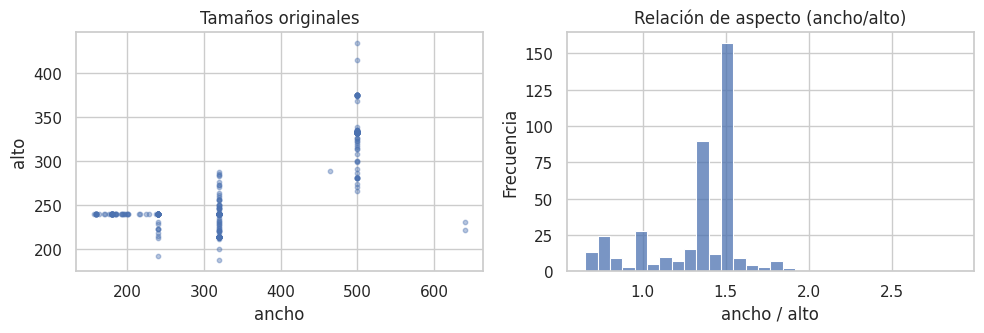

In [ ]:
# Tamaños originales (muestra de 400 imágenes) y canales
muestra = df.sample(400, random_state=SEED)["path"]
tam = np.array([Image.open(p).size for p in muestra])
print(f"Ancho : min={tam[:,0].min()}, media={tam[:,0].mean():.0f}, max={tam[:,0].max()}")
print(f"Alto  : min={tam[:,1].min()}, media={tam[:,1].mean():.0f}, max={tam[:,1].max()}")
print("Modos de color:", {Image.open(p).mode for p in muestra})
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].scatter(tam[:, 0], tam[:, 1], alpha=.4, s=10); axes[0].set(title="Tamaños originales", xlabel="ancho", ylabel="alto")
sns.histplot(tam[:, 0] / tam[:, 1], bins=30, ax=axes[1]); axes[1].set(title="Relación de aspecto (ancho/alto)", xlabel="ancho / alto", ylabel="Frecuencia"); plt.tight_layout(); plt.show()

**Observaciones:** las imágenes tienen tamaños y proporciones distintos, así que hay que **redimensionarlas** a un tamaño fijo. Las clases están razonablemente equilibradas (no hace falta `class_weight`).

## 3. Preprocesamiento y normalización

1. **Redimensionado** a 128×128 (la CNN necesita entrada de tamaño fijo; 128 equilibra detalle y velocidad).
2. **Normalización:** los píxeles (0–255) se dividen entre 255 con una capa `Rescaling` **dentro del modelo**. Así el modelo guardado recibe píxeles crudos y la app no puede equivocarse al normalizar.
3. Las imágenes se guardan en caché como `uint8` para acelerar las épocas.

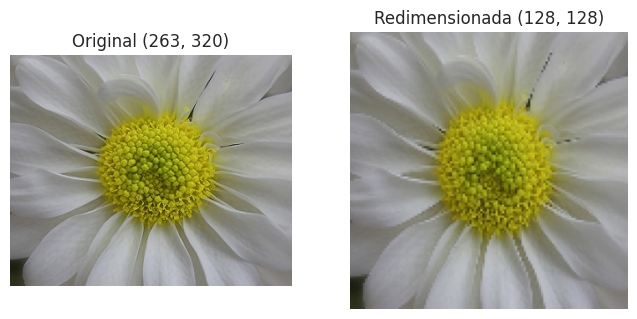

Rango de píxeles tras redimensionar: 0 - 210 → se normaliza a 0-1 dentro del modelo


In [ ]:
def resize_image(img):
    img = tf.image.resize(tf.cast(img, tf.float32), (IMG_SIZE, IMG_SIZE))
    return tf.cast(tf.round(tf.clip_by_value(img, 0.0, 255.0)), tf.uint8)

ej = np.array(Image.open(df.path.iloc[0]).convert("RGB"))
fig, axes = plt.subplots(1, 2, figsize=(8, 3.6))
axes[0].imshow(ej); axes[0].set_title(f"Original {ej.shape[:2]}")
axes[1].imshow(resize_image(ej).numpy()); axes[1].set_title(f"Redimensionada ({IMG_SIZE}, {IMG_SIZE})")
for a in axes: a.axis("off")
plt.show()
print("Rango de píxeles tras redimensionar:", resize_image(ej).numpy().min(), "-", resize_image(ej).numpy().max(), "→ se normaliza a 0-1 dentro del modelo")

## 4. División en entrenamiento, validación y prueba

70 % / 15 % / 15 % **estratificada** (misma proporción de clases en cada conjunto). El conjunto de prueba solo se usa al final.

In [ ]:
paths, labels = df["path"].values, df["label"].values.astype("int32")
p_tr, p_tmp, y_tr, y_tmp = train_test_split(paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
p_va, p_te, y_va, y_te = train_test_split(p_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
for n, y in [("Train", y_tr), ("Val", y_va), ("Test", y_te)]:
    print(f"{n:5}: {len(y):5} imágenes |", dict(zip(NOMBRES, np.bincount(y))))

def make_ds(p, y, shuffle=False):
    def _load(path, label):
        img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False); img.set_shape([None, None, 3])
        return resize_image(img), label
    ds = tf.data.Dataset.from_tensor_slices((np.array(p, dtype=str), np.array(y, dtype="int32")))
    ds = ds.map(_load, num_parallel_calls=tf.data.AUTOTUNE).cache()
    if shuffle: ds = ds.shuffle(len(p), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH).map(lambda x, l: (tf.cast(x, tf.float32), l), num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(p_tr, y_tr, True), make_ds(p_va, y_va), make_ds(p_te, y_te)

Train:  2569 imágenes | {'Margarita': np.int64(443), 'Diente de león': np.int64(629), 'Rosa': np.int64(449), 'Girasol': np.int64(489), 'Tulipán': np.int64(559)}
Val  :   550 imágenes | {'Margarita': np.int64(95), 'Diente de león': np.int64(134), 'Rosa': np.int64(96), 'Girasol': np.int64(105), 'Tulipán': np.int64(120)}
Test :   551 imágenes | {'Margarita': np.int64(95), 'Diente de león': np.int64(135), 'Rosa': np.int64(96), 'Girasol': np.int64(105), 'Tulipán': np.int64(120)}


## 5. Data Augmentation (aumento de datos)

Con solo ~2.500 imágenes de entrenamiento, una CNN grande tiende a **memorizar** (sobreajuste). El Data Augmentation genera variaciones plausibles de cada foto (volteo, rotación, zoom, desplazamiento, contraste) y obliga al modelo a aprender patrones más generales.
Las capas de augmentation **solo actúan en entrenamiento**; en validación, prueba y en la app no hacen nada.
En la sección 6 lo comprobamos con un experimento: **con vs. sin augmentation**.

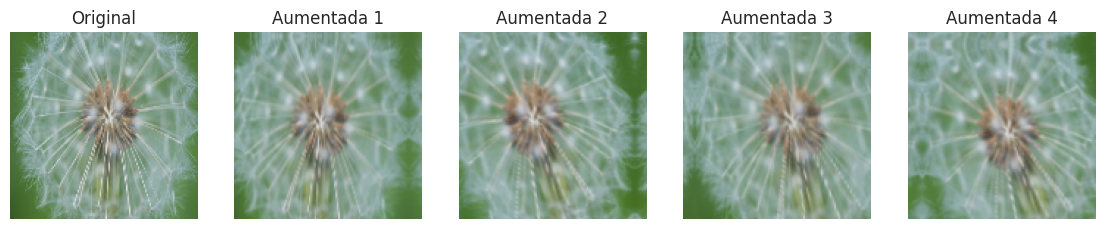

In [ ]:
def build_augmentation():
    return keras.Sequential([layers.RandomFlip("horizontal"), layers.RandomRotation(0.08), layers.RandomZoom(0.15),
                             layers.RandomTranslation(0.1, 0.1), layers.RandomContrast(0.15)], name="data_augmentation")

aug = build_augmentation()
img = resize_image(np.array(Image.open(p_tr[0]).convert("RGB"))).numpy().astype("float32")
lote = aug(tf.repeat(img[None], 8, axis=0), training=True).numpy().clip(0, 255).astype("uint8")
fig, axes = plt.subplots(1, 5, figsize=(14, 3))
axes[0].imshow(img.astype("uint8")); axes[0].set_title("Original")
for k in range(1, 5): axes[k].imshow(lote[k]); axes[k].set_title(f"Aumentada {k}")
for a in axes: a.axis("off")
plt.show()

## 6. Construcción y entrenamiento de la CNN

Arquitectura: `[Augmentation] → Rescaling(1/255) → 4 bloques [Conv-BN-ReLU ×2 → MaxPool → Dropout(0.2)] (32, 64, 128, 256 filtros) → GlobalAveragePooling → Dense(128) → Dropout(0.4) → Dense(5, softmax)`

- `BatchNormalization` estabiliza y acelera el entrenamiento; `GlobalAveragePooling` reduce parámetros frente a `Flatten`.
- Adam (1e-3) con `ReduceLROnPlateau`, `EarlyStopping` (patience=6, restaura los mejores pesos) y `ModelCheckpoint`.
- Se comparan **sin** y **con** augmentation y se elige por **accuracy de validación** (nunca con test).

In [ ]:
def build_model(augment=True, dropout=0.4, lr=1e-3):
    inp = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="imagen")
    x = build_augmentation()(inp) if augment else inp
    x = layers.Rescaling(1.0 / 255, name="normalizacion")(x)
    for f in (32, 64, 128, 256):
        for _ in range(2):
            x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x); x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
        x = layers.MaxPooling2D()(x); x = layers.Dropout(0.2)(x)
    x = layers.GlobalAveragePooling2D()(x); x = layers.Dense(128, activation="relu")(x); x = layers.Dropout(dropout)(x)
    out = layers.Dense(len(CLASS_NAMES), activation="softmax", name="probabilidades")(x)
    m = keras.Model(inp, out, name="cnn_flores" + ("_aug" if augment else "_sin_aug"))
    m.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

build_model(True).summary()

Model: "cnn_flores_aug"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)             │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalizacion (Rescaling)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,208,677 (4.61 MB)

 Trainable params: 1,206,757 (4.60 MB)

 Non-trainable params: 1,920 (7.50 KB)

In [ ]:
os.makedirs("modelo", exist_ok=True)
modelos, historias, resumen = {}, {}, []
for nombre, augment in [("sin_aumento_de_datos", False), ("con_aumento_de_datos", True)]:
    print(f"\n===== Entrenando: {nombre} =====")
    tf.keras.utils.set_random_seed(SEED)
    m = build_model(augment)
    cb = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
          keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
          keras.callbacks.ModelCheckpoint(f"modelo/ckpt_{nombre}.keras", monitor="val_loss", save_best_only=True)]
    h = m.fit(train_ds, validation_data=val_ds, epochs=40, callbacks=cb, verbose=2)
    vl, va = m.evaluate(val_ds, verbose=0)
    modelos[nombre], historias[nombre] = m, h
    resumen.append({"experimento": nombre, "épocas": len(h.history["loss"]), "train_acc": h.history["accuracy"][-1],
                    "val_loss": vl, "val_accuracy": va, "brecha_train_val": h.history["accuracy"][-1] - va})
tabla = pd.DataFrame(resumen).set_index("experimento").round(4); tabla


===== Entrenando: sin_aumento_de_datos =====
Epoch 1/40
81/81 - 296s - 4s/step - accuracy: 0.4963 - loss: 1.2654 - val_accuracy: 0.2436 - val_loss: 2.1283 - learning_rate: 0.0010
Epoch 2/40
81/81 - 326s - 4s/step - accuracy: 0.5823 - loss: 1.0691 - val_accuracy: 0.2436 - val_loss: 3.8559 - learning_rate: 0.0010
Epoch 3/40
81/81 - 294s - 4s/step - accuracy: 0.6201 - loss: 0.9772 - val_accuracy: 0.2455 - val_loss: 2.1824 - learning_rate: 0.0010
Epoch 4/40
81/81 - 286s - 4s/step - accuracy: 0.6458 - loss: 0.8996 - val_accuracy: 0.4145 - val_loss: 1.4962 - learning_rate: 0.0010
Epoch 5/40
81/81 - 325s - 4s/step - accuracy: 0.6641 - loss: 0.8616 - val_accuracy: 0.3582 - val_loss: 2.4516 - learning_rate: 0.0010
Epoch 6/40
81/81 - 288s - 4s/step - accuracy: 0.6633 - loss: 0.8388 - val_accuracy: 0.5709 - val_loss: 1.1274 - learning_rate: 0.0010
Epoch 7/40
81/81 - 280s - 3s/step - accuracy: 0.6882 - loss: 0.7934 - val_accuracy: 0.6691 - val_loss: 1.0252 - learning_rate: 0.0010
Epoch 8/40
81/81

,épocas,train_acc,val_loss,val_accuracy,brecha_train_val
experimento,,,,,
sin_aumento_de_datos,33,0.9023,0.5895,0.8200,0.0823
con_aumento_de_datos,26,0.7898,0.6447,0.7618,0.0280


## 7. Gráficas del entrenamiento

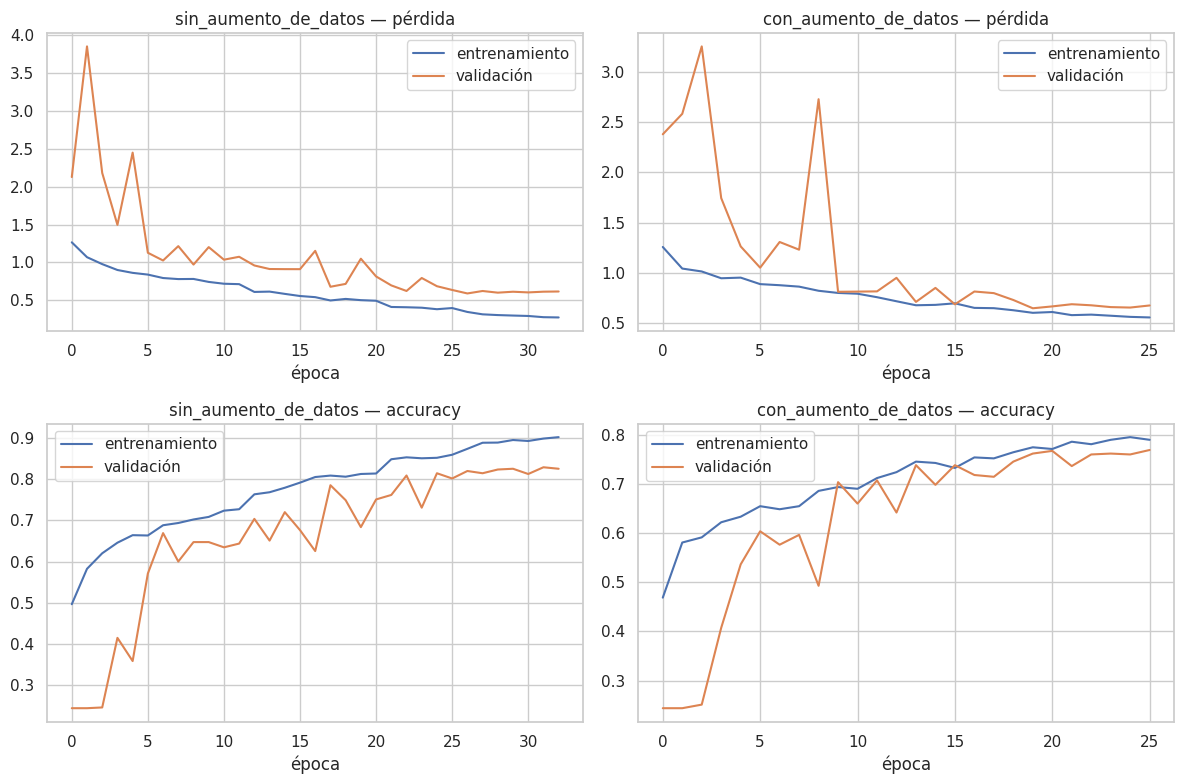

✅ Mejor experimento según accuracy de validación: sin_aumento_de_datos


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for j, (n, h) in enumerate(historias.items()):
    axes[0, j].plot(h.history["loss"], label="entrenamiento"); axes[0, j].plot(h.history["val_loss"], label="validación")
    axes[0, j].set(title=f"{n} — pérdida", xlabel="época"); axes[0, j].legend()
    axes[1, j].plot(h.history["accuracy"], label="entrenamiento"); axes[1, j].plot(h.history["val_accuracy"], label="validación")
    axes[1, j].set(title=f"{n} — accuracy", xlabel="época"); axes[1, j].legend()
plt.tight_layout(); plt.show()
mejor = tabla["val_accuracy"].idxmax(); print(f"✅ Mejor experimento según accuracy de validación: {mejor}")

**Cómo leer las curvas:** una brecha grande entre *entrenamiento* y *validación* indica sobreajuste. El Data Augmentation suele reducirla (columna `brecha_train_val`). Si el modelo con augmentation no mejora en validación, elegimos el otro: la decisión la manda el resultado, no la teoría.

## 8. Evaluación en el conjunto de prueba y matriz de confusión

                      precisión  recall      f1  soporte
Margarita                0.9221  0.7474  0.8256       95
Diente de león           0.7605  0.9407  0.8411      135
Rosa                     0.7059  0.7500  0.7273       96
Girasol                  0.9479  0.8667  0.9055      105
Tulipán                  0.8165  0.7417  0.7773      120
Promedio macro           0.8306  0.8093  0.8153      551
Promedio ponderado       0.8268  0.8167  0.8170      551
Exactitud (accuracy)        NaN     NaN  0.8167      551


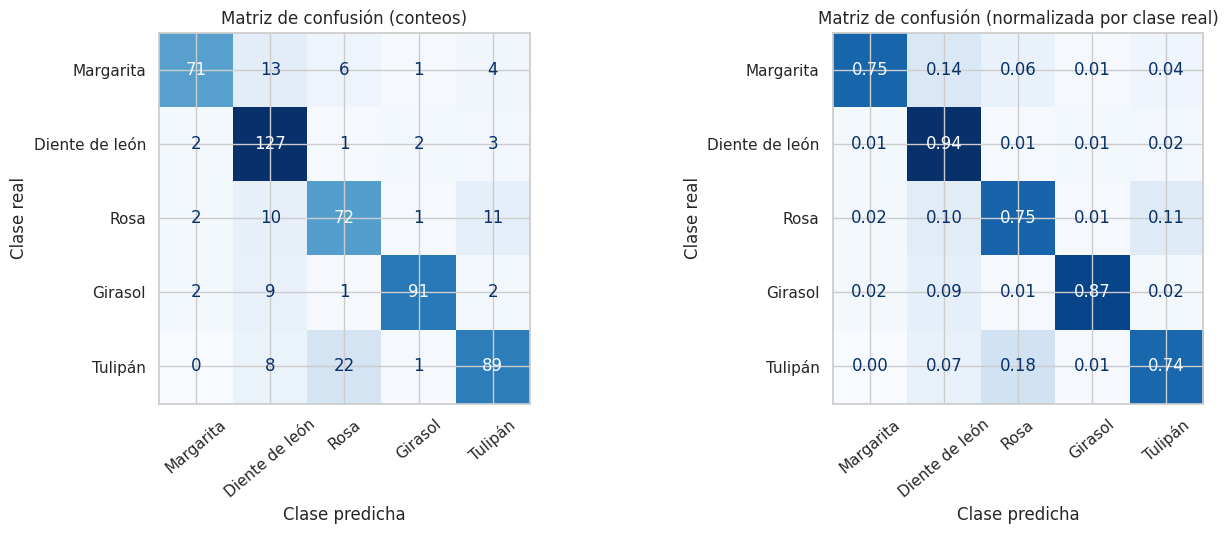

In [ ]:
best = modelos[mejor]
probs = best.predict(test_ds, verbose=0); preds = probs.argmax(1)
metrics = {"experimento": mejor, "accuracy": accuracy_score(y_te, preds), "precision_macro": precision_score(y_te, preds, average="macro"),
           "recall_macro": recall_score(y_te, preds, average="macro"), "f1_macro": f1_score(y_te, preds, average="macro"),
           "f1_weighted": f1_score(y_te, preds, average="weighted"), "confusion_matrix": confusion_matrix(y_te, preds).tolist(), "n_test": int(len(y_te))}
def reporte_es(y_true, y_pred):
    r = classification_report(y_true, y_pred, labels=list(range(len(NOMBRES))), target_names=NOMBRES, output_dict=True, zero_division=0)
    filas = {n: r[n] for n in NOMBRES}; filas["Promedio macro"] = r["macro avg"]; filas["Promedio ponderado"] = r["weighted avg"]
    out = pd.DataFrame({k: {"precisión": v["precision"], "recall": v["recall"], "f1": v["f1-score"], "soporte": int(v["support"])} for k, v in filas.items()}).T
    out.loc["Exactitud (accuracy)"] = [np.nan, np.nan, r["accuracy"], len(y_true)]
    out["soporte"] = out["soporte"].astype(int)
    return out.round(4)

reporte = reporte_es(y_te, preds); print(reporte.to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
ConfusionMatrixDisplay.from_predictions(y_te, preds, display_labels=NOMBRES, cmap="Blues", ax=axes[0], colorbar=False, xticks_rotation=40); axes[0].set_title("Matriz de confusión (conteos)")
ConfusionMatrixDisplay.from_predictions(y_te, preds, display_labels=NOMBRES, cmap="Blues", ax=axes[1], colorbar=False, normalize="true", values_format=".2f", xticks_rotation=40)
axes[1].set_title("Matriz de confusión (normalizada por clase real)")
for a in axes: a.set(xlabel="Clase predicha", ylabel="Clase real")
plt.tight_layout(); plt.show()

**Interpretación:** en la diagonal están los aciertos. Fíjate qué pares de clases se confunden más (p. ej. rosas con tulipanes o margaritas con dientes de león, por forma y color parecidos). Usamos precisión, recall y F1 **por clase** porque la accuracy sola oculta qué clases fallan.

## 9. Predicciones con imágenes (≥ 10)

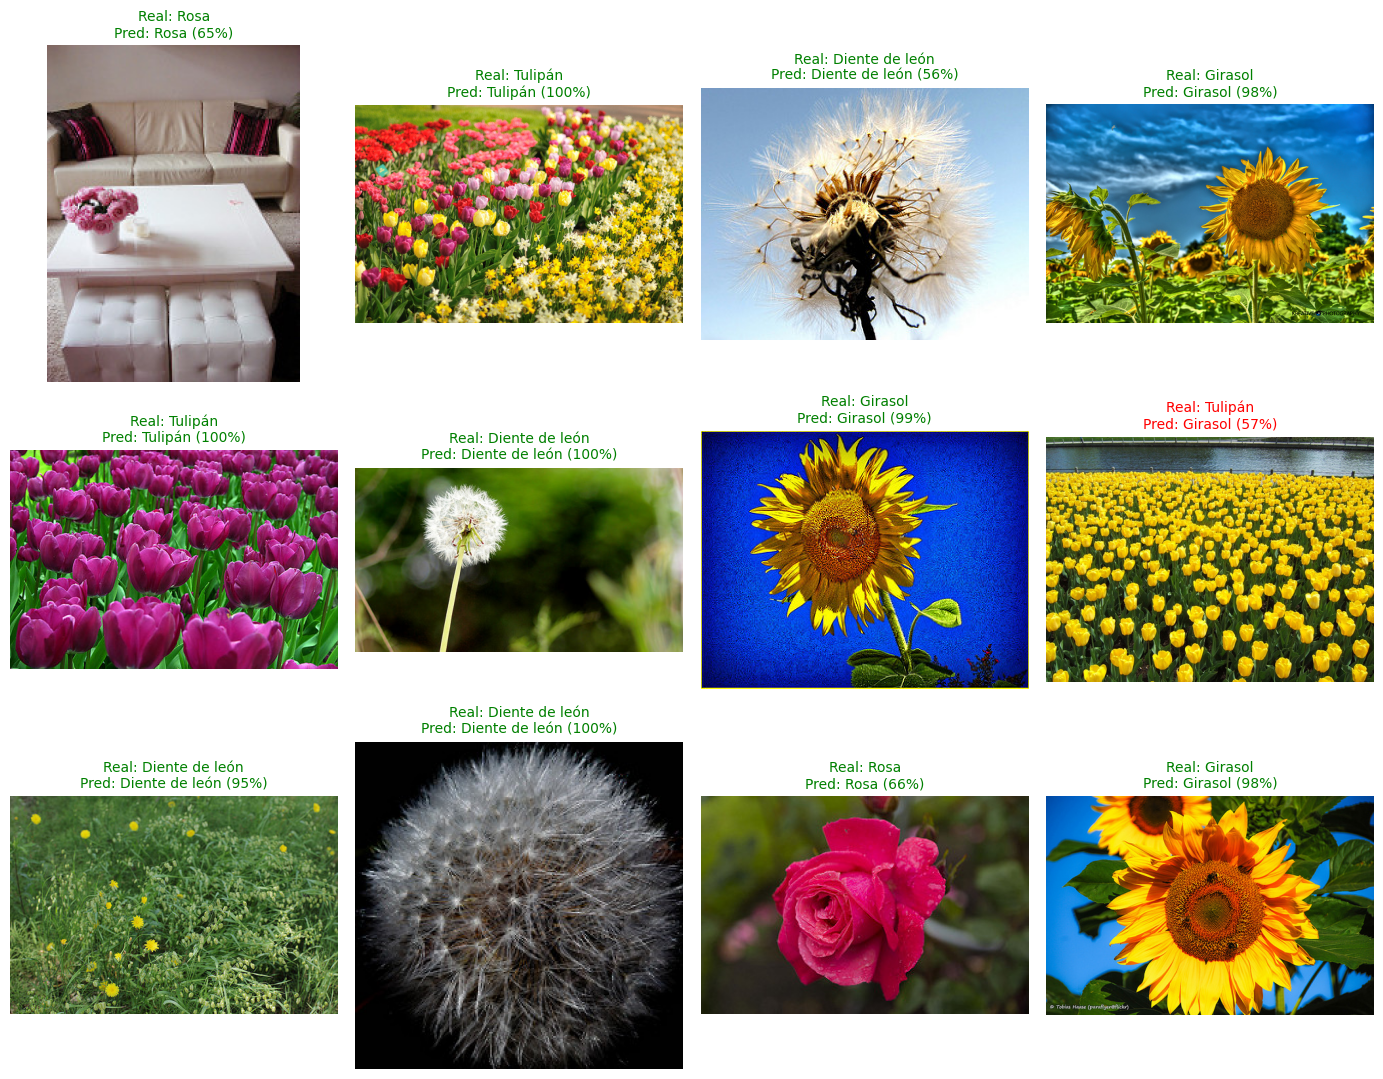

,archivo,real,prediccion,confianza,correcta
0,3102535578_ec8c12a7b6_m.jpg,Rosa,Rosa,0.6528,True
1,5674127693_1ddbd81097.jpg,Tulipán,Tulipán,0.9995,True
2,5446666484_365f3be83a_n.jpg,Diente de león,Diente de león,0.5624,True
3,5738580862_e128192f75.jpg,Girasol,Girasol,0.9756,True
4,11746276_de3dec8201.jpg,Tulipán,Tulipán,1.0000,True
5,16510864164_3afa8ac37f.jpg,Diente de león,Diente de león,0.9993,True
6,14925397351_c7f209d804_n.jpg,Girasol,Girasol,0.9931,True
7,142235914_5419ff8a4a.jpg,Tulipán,Girasol,0.5669,False
8,18001393975_2a6acaabd8.jpg,Diente de león,Diente de león,0.9505,True
9,7367491658_9eb4dc2384_m.jpg,Diente de león,Diente de león,0.9997,True


In [ ]:
idx = np.random.RandomState(SEED).choice(len(p_te), 12, replace=False)
fig, axes = plt.subplots(3, 4, figsize=(14, 11)); registros = []
for ax, i in zip(axes.ravel(), idx):
    pr = int(preds[i]); ok = pr == int(y_te[i])
    ax.imshow(Image.open(p_te[i]).convert("RGB")); ax.axis("off")
    ax.set_title(f"Real: {NOMBRES[y_te[i]]}\nPred: {NOMBRES[pr]} ({probs[i][pr]:.0%})", fontsize=10, color="green" if ok else "red")
    registros.append({"archivo": Path(p_te[i]).name, "real": NOMBRES[y_te[i]], "prediccion": NOMBRES[pr], "confianza": round(float(probs[i][pr]), 4), "correcta": ok})
plt.tight_layout(); plt.show()
tabla_pred = pd.DataFrame(registros); tabla_pred

Errores: 101 de 551


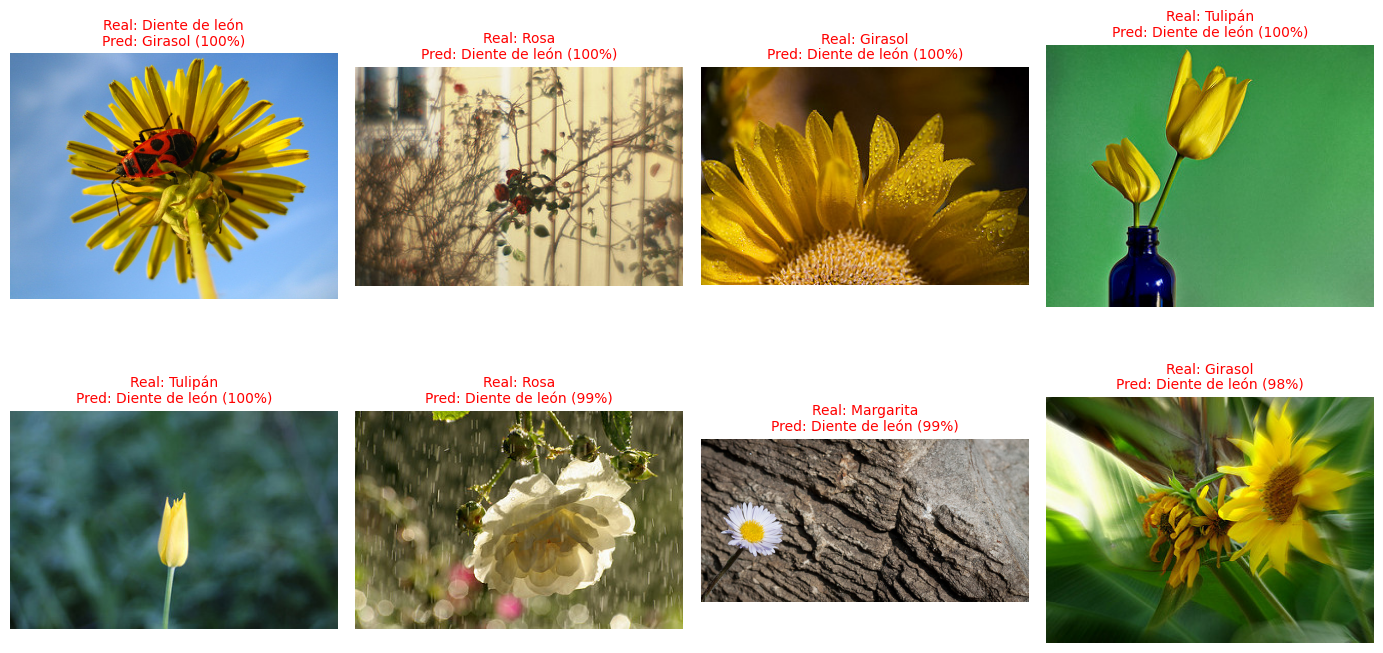

In [ ]:
# Análisis de errores: los 8 fallos con mayor confianza
err = np.where(preds != y_te)[0]
print(f"Errores: {len(err)} de {len(y_te)}")
top = err[np.argsort(-probs[err].max(1))][:8]
fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
for ax, i in zip(axes.ravel(), top):
    ax.imshow(Image.open(p_te[i]).convert("RGB")); ax.axis("off")
    ax.set_title(f"Real: {NOMBRES[y_te[i]]}\nPred: {NOMBRES[preds[i]]} ({probs[i].max():.0%})", fontsize=10, color="red")
for ax in axes.ravel()[len(top):]: ax.axis("off")
plt.tight_layout(); plt.show()

## 10. Guardado del modelo

Se guarda en formato `.keras`, con la normalización incluida. Se verifica que al recargarlo produce las mismas predicciones y se copian 10 imágenes de test a `ejemplos/` para probar la app.

In [ ]:
os.makedirs("reports", exist_ok=True); os.makedirs("ejemplos", exist_ok=True)
best.save("modelo/modelo_flores.keras")
config = {"img_size": IMG_SIZE, "class_names": CLASS_NAMES, "nombres_es": NOMBRES, "augmentation": mejor == "con_aumento_de_datos",
          "batch_size": BATCH, "seed": SEED, "epochs_entrenadas": len(historias[mejor].history["loss"])}
json.dump(config, open("modelo/config.json", "w"), indent=2, ensure_ascii=False)
json.dump(metrics, open("reports/metrics.json", "w"), indent=2)
tabla.to_csv("reports/comparacion_experimentos.csv"); reporte.to_csv("reports/reporte_clasificacion.csv"); tabla_pred.to_csv("reports/predicciones_test.csv", index=False)

for i, cls in enumerate(CLASS_NAMES):
    for n, p in enumerate(p_te[y_te == i][:2], start=1): shutil.copy(p, f"ejemplos/{ARCHIVO_ES[cls]}_{n}{Path(p).suffix.lower()}")

reloaded = keras.models.load_model("modelo/modelo_flores.keras")
print("Diferencia máx. original vs recargado:", float(np.abs(probs - reloaded.predict(test_ds, verbose=0)).max()))
print("Ejemplos guardados:", sorted(os.listdir("ejemplos")))

In [ ]:
# Guardar también las gráficas clave en reports/ y descargar todo
plt.figure(figsize=(12, 4.5))
for n, h in historias.items():
    plt.subplot(1, 2, 1); plt.plot(h.history["val_loss"], label=n); plt.title("Pérdida de validación"); plt.xlabel("época"); plt.legend()
    plt.subplot(1, 2, 2); plt.plot(h.history["val_accuracy"], label=n); plt.title("Accuracy de validación"); plt.xlabel("época"); plt.legend()
plt.tight_layout(); plt.savefig("reports/curvas_entrenamiento.png", dpi=130); plt.close()

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_te, preds, display_labels=NOMBRES, cmap="Blues", ax=ax, colorbar=False, xticks_rotation=40)
ax.set(xlabel="Clase predicha", ylabel="Clase real"); plt.title("Matriz de confusión (test)"); plt.tight_layout(); plt.savefig("reports/matriz_confusion.png", dpi=130); plt.close()

for f in os.listdir("modelo"):
    if f.startswith("ckpt_"): os.remove(os.path.join("modelo", f))
for carpeta in ["modelo", "reports", "ejemplos"]: shutil.make_archive(f"{carpeta}_proyecto", "zip", ".", carpeta)
try:
    from google.colab import files
    for carpeta in ["modelo", "reports", "ejemplos"]: files.download(f"{carpeta}_proyecto.zip")
except ImportError:
    print("Fuera de Colab: los archivos están en ./modelo, ./reports y ./ejemplos")

## 11. Conclusiones

- Resume la accuracy y el F1 macro en test, y qué experimento ganó (con o sin augmentation) y por cuánto.
- Indica qué clases se confunden más y por qué (color/forma parecidos).
- Limitaciones: solo 5 clases (cualquier otra imagen se clasificará igualmente como una flor), dataset pequeño, CNN entrenada desde cero.
- Mejoras: *transfer learning* (MobileNetV2/EfficientNet), mayor resolución, más datos o una clase "otro".

**Siguiente paso:** descomprime `modelo_proyecto.zip`, `reports_proyecto.zip` y `ejemplos_proyecto.zip` en la raíz del repositorio y ejecuta `streamlit run app.py`.